# Bagian E — Temporal Association Analysis

Notebook ini menganalisis perubahan pola asosiasi antar-konferensi pada dataset DBLP (publikasi *inproceedings* 2015–2025) menggunakan **Author-Year-Based Transactional Database**. Transaksi dibagi ke empat periode, yaitu 2015–2017, 2018–2020, 2021–2023, dan 2024–2025. Pada setiap periode diterapkan algoritma FP-Growth dan pembangkitan association rules dengan parameter yang sama (minimum support 0,1% dan minimum confidence 50%), sehingga hasil antarperiode dapat dibandingkan secara adil.

Struktur notebook mengikuti urutan butir tugas pada Bagian E:

| Bagian notebook | Butir tugas Bagian E |
|---|---|
| 0. Persiapan data dan konfigurasi | Prasyarat (Author-Year-Based Transactional Database) |
| 1. Frequent Pattern Mining pada setiap periode | Butir 1 |
| 2. Frequent itemsets pada setiap periode | Butir 2 |
| 3. Association rules pada setiap periode | Butir 3 |
| 4. Perbandingan association rules antarperiode | Butir 4 |
| 5. Pola yang bertahan dan pola yang berubah | Butir 5 |
| 6. Kemungkinan perubahan tren publikasi | Butir 6 |
| 7. Kesimpulan dan keterbatasan | Ringkasan |

Notebook memuat kembali `data/processed/tx_author_year_based.pkl` (daftar transaksi) beserta sidecar `tx_author_year_years.pkl` (tahun tiap transaksi, urutannya sejajar) yang dihasilkan pada Task 3. Seluruh tabel hasil disimpan di `data/results/` dengan awalan `bagianE_`, sedangkan grafik disimpan di `figures/` dengan awalan yang sama.

## 0. Persiapan data dan konfigurasi

Bagian ini memuat modul proyek, menetapkan periode dan parameter mining, serta membaca transaksi beserta tahunnya. Pembacaan dua berkas dilakukan bersamaan dan divalidasi agar jumlah transaksi dan jumlah tahun identik. Parameter minimum support dan minimum confidence dibuat konstan di semua periode agar perbedaan hasil mencerminkan perbedaan data, bukan perbedaan ambang.

In [17]:
from pathlib import Path
import json
import pickle
import sys

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display

pd.set_option('display.max_columns', None)
pd.set_option('display.width', 220)

cwd = Path.cwd().resolve()
PROJECT_ROOT = next(
    (path for path in (cwd, *cwd.parents)
     if (path / 'src' / 'fpgrowth.py').is_file() and (path / 'data').is_dir()),
    None,
)
if PROJECT_ROOT is None:
    raise FileNotFoundError('Folder proyek tidak ditemukan dari current working directory.')
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

from src.association_rules import generate_rules
from src.fpgrowth import run_fpgrowth
from src.transactions import load_transactions

PROCESSED_DIR = PROJECT_ROOT / 'data' / 'processed'
TRANSACTIONS_PATH = PROCESSED_DIR / 'tx_author_year_based.pkl'
YEARS_PATH = PROCESSED_DIR / 'tx_author_year_years.pkl'
RESULTS_DIR = PROJECT_ROOT / 'data' / 'results'
FIGURES_DIR = PROJECT_ROOT / 'figures'
RESULTS_DIR.mkdir(parents=True, exist_ok=True)
FIGURES_DIR.mkdir(parents=True, exist_ok=True)

PERIODS = [
    ('2015-2017', 2015, 2017),
    ('2018-2020', 2018, 2020),
    ('2021-2023', 2021, 2023),
    ('2024-2025', 2024, 2025),
]
PERIOD_NAMES = [period[0] for period in PERIODS]
MIN_SUPPORT = 0.001
MIN_CONFIDENCE = 0.50
SENSITIVITY_CONFIDENCE = 0.30  # hanya untuk analisis tambahan pada bagian 4.3

missing_files = [str(path) for path in [TRANSACTIONS_PATH, YEARS_PATH] if not path.is_file()]
if missing_files:
    raise FileNotFoundError('Output Task 3 belum tersedia:\n' + '\n'.join(missing_files))

transactions = load_transactions(TRANSACTIONS_PATH)
with YEARS_PATH.open('rb') as years_file:
    transaction_years = pickle.load(years_file)
if len(transactions) != len(transaction_years):
    raise ValueError('Jumlah transaksi dan metadata tahun berbeda; jalankan ulang notebook 03_transactional_db.')

print(f'Author-Year transactions loaded: {len(transactions):,}')
print(f'Minimum support: {MIN_SUPPORT:.1%} | minimum confidence: {MIN_CONFIDENCE:.0%}')

Author-Year transactions loaded: 4,085,395
Minimum support: 0.1% | minimum confidence: 50%


## 1. Frequent Pattern Mining pada setiap periode (Butir 1)

Setiap transaksi author-tahun dialokasikan ke tepat satu periode berdasarkan tahunnya. Jika ditemukan tahun di luar rentang 2015–2025, proses dihentikan agar tidak ada transaksi yang hilang secara diam-diam. Algoritma FP-Growth dijalankan secara terpisah pada tiap periode dengan minimum support relatif 0,1%. Karena jumlah transaksi berbeda antarperiode, ambang support absolut ikut berbeda; hal ini dicatat pada tabel ringkasan.

Untuk menghemat memori, daftar transaksi per periode dibuang segera setelah mining selesai, dan hanya hasil frequent itemsets yang disimpan.

In [18]:
def format_venues(codes):
    return ', '.join(sorted(codes))


transactions_by_period = {name: [] for name in PERIOD_NAMES}
for year, transaction in zip(transaction_years, transactions):
    year = int(year)
    for name, start_year, end_year in PERIODS:
        if start_year <= year <= end_year:
            transactions_by_period[name].append(transaction)
            break
    else:
        raise ValueError(f'Tahun transaksi di luar periode analisis: {year}')
del transactions, transaction_years

freq_by_period = {}   # periode -> {itemset: support_count}
freq_lookup = {}      # periode -> {frozenset(itemset): support_count}
TX_COUNTS = {}        # periode -> jumlah transaksi
summary_rows = []

for name, start_year, end_year in PERIODS:
    period_transactions = transactions_by_period.pop(name)
    if not period_transactions:
        raise ValueError(f'Tidak ada transaksi untuk periode {name}.')

    frequent_itemsets = run_fpgrowth(period_transactions, min_support=MIN_SUPPORT)
    freq_by_period[name] = frequent_itemsets
    freq_lookup[name] = {frozenset(key): value for key, value in frequent_itemsets.items()}
    TX_COUNTS[name] = len(period_transactions)

    summary_rows.append({
        'period': name,
        'start_year': start_year,
        'end_year': end_year,
        'transactions': len(period_transactions),
        'min_count_perkiraan': int(np.ceil(MIN_SUPPORT * len(period_transactions))),
        'unique_venues': len({venue for transaction in period_transactions for venue in transaction}),
        'frequent_itemsets': len(frequent_itemsets),
        'frequent_singletons': sum(len(itemset) == 1 for itemset in frequent_itemsets),
        'multi_venue_itemsets': sum(len(itemset) >= 2 for itemset in frequent_itemsets),
        'max_itemset_size': max((len(itemset) for itemset in frequent_itemsets), default=0),
    })
    print(f'{name}: {len(period_transactions):,} transaksi, {len(frequent_itemsets):,} frequent itemsets')
    del period_transactions

summary_df = pd.DataFrame(summary_rows)
display(summary_df)

2015-2017: 922,044 transaksi, 357 frequent itemsets
2018-2020: 1,080,818 transaksi, 327 frequent itemsets
2021-2023: 1,195,896 transaksi, 359 frequent itemsets
2024-2025: 886,637 transaksi, 487 frequent itemsets


,period,start_year,end_year,transactions,min_count_perkiraan,unique_venues,frequent_itemsets,frequent_singletons,multi_venue_itemsets,max_itemset_size
0,2015-2017,2015,2017,922044,923,2680,357,346,11,2
1,2018-2020,2018,2020,1080818,1081,2897,327,305,22,2
2,2021-2023,2021,2023,1195896,1196,3033,359,311,48,3
3,2024-2025,2024,2025,886637,887,2594,487,294,193,4


## 2. Frequent itemsets pada setiap periode (Butir 2)

Frequent itemsets seluruh periode digabung dalam satu tabel, kemudian ditampilkan per periode dalam dua sudut pandang: (a) sepuluh itemset dengan support tertinggi dari semua ukuran, yang didominasi venue tunggal, dan (b) sepuluh kombinasi multi-venue (ukuran ≥ 2) dengan support tertinggi, yang menunjukkan konferensi yang sering dipublikasikan oleh author yang sama dalam tahun yang sama.

In [19]:
itemset_rows = []
for period_name in PERIOD_NAMES:
    for itemset, count in freq_by_period[period_name].items():
        itemset_rows.append({
            'period': period_name,
            'itemset_codes': json.dumps(sorted(itemset), ensure_ascii=False),
            'itemset': format_venues(itemset),
            'size': len(itemset),
            'support_count': count,
            'support': count / TX_COUNTS[period_name],
        })

itemsets_df = pd.DataFrame(itemset_rows).sort_values(
    ['period', 'support_count', 'size', 'itemset'], ascending=[True, False, False, True]
).reset_index(drop=True)
itemsets_df.to_csv(RESULTS_DIR / 'bagianE_frequent_itemsets.csv', index=False)

for period_name in PERIOD_NAMES:
    period_df = itemsets_df[itemsets_df['period'] == period_name]
    print(f'{period_name}: Top-10 frequent itemsets (semua ukuran)')
    display(period_df[['itemset', 'size', 'support_count', 'support']].head(10).reset_index(drop=True))

    multi_df = period_df[period_df['size'] >= 2]
    print(f'{period_name}: Top-10 kombinasi multi-venue')
    if multi_df.empty:
        print('Tidak ada frequent itemset berukuran >= 2 pada periode ini.')
    else:
        display(multi_df[['itemset', 'size', 'support_count', 'support']].head(10).reset_index(drop=True))
    print('')

2015-2017: Top-10 frequent itemsets (semua ukuran)


,itemset,size,support_count,support
0,embc,1,17285,0.018746
1,igarss,1,13783,0.014948
2,hci,1,12213,0.013246
3,icc,1,12003,0.013018
4,globecom,1,10534,0.011425
5,iecon,1,10010,0.010856
6,icassp,1,9921,0.010760
7,chi,1,9372,0.010164
8,vtc,1,8561,0.009285
9,iros,1,8525,0.009246


2015-2017: Top-10 kombinasi multi-venue


,itemset,size,support_count,support
0,"globecom, icc",2,2957,0.003207
1,"amcc, cdc",2,1880,0.002039
2,"icra, iros",2,1780,0.001930
3,"ecoc, ofc",2,1721,0.001867
4,"globecom, vtc",2,1544,0.001675
5,"icc, vtc",2,1542,0.001672
6,"aaai, ijcai",2,1450,0.001573
7,"icassp, interspeech",2,1296,0.001406
8,"cvpr, iccv",2,1226,0.001330
9,"icc, wcnc",2,956,0.001037



2018-2020: Top-10 frequent itemsets (semua ukuran)


,itemset,size,support_count,support
0,igarss,1,19200,0.017764
1,embc,1,17516,0.016206
2,cvpr,1,17215,0.015928
3,aaai,1,15153,0.014020
4,nips,1,14326,0.013255
5,icassp,1,14159,0.013100
6,hci,1,14087,0.013034
7,chi,1,12401,0.011474
8,miccai,1,11574,0.010709
9,globecom,1,11533,0.010671


... (6 outputs left out)


2024-2025: Top-10 frequent itemsets (semua ukuran)


,itemset,size,support_count,support
0,nips,1,43738,0.049330
1,cvpr,1,30414,0.034303
2,aaai,1,25883,0.029192
3,iclr,1,25371,0.028615
4,emnlp,1,24605,0.027751
5,icml,1,24002,0.027071
6,acl,1,22169,0.025003
7,icassp,1,21817,0.024606
8,iccv,1,15260,0.017211
9,miccai,1,14759,0.016646


2024-2025: Top-10 kombinasi multi-venue


,itemset,size,support_count,support
0,"iclr, nips",2,9264,0.010448
1,"icml, nips",2,8745,0.009863
2,"cvpr, nips",2,7380,0.008324
3,"acl, emnlp",2,7152,0.008066
4,"iclr, icml",2,6497,0.007328
5,"aaai, nips",2,6286,0.007090
6,"emnlp, nips",2,5096,0.005748
7,"acl, nips",2,5053,0.005699
8,"cvpr, iccv",2,4686,0.005285
9,"aaai, cvpr",2,4631,0.005223


### 2.1 Distribusi ukuran frequent itemsets per periode

Distribusi ukuran itemset memperlihatkan seberapa banyak pola yang melibatkan lebih dari satu venue. Pertambahan itemset berukuran 2 ke atas menandakan makin kuatnya kebiasaan author mempublikasikan karya pada beberapa venue sekaligus dalam tahun yang sama.

,1-itemset,2-itemset,3-itemset,4-itemset
period,,,,
2015-2017,346,11,0,0
2018-2020,305,22,0,0
2021-2023,311,45,3,0
2024-2025,294,128,55,10


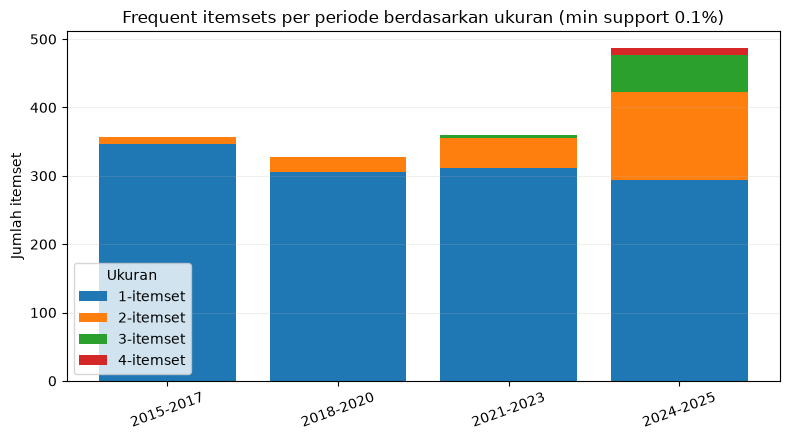

In [20]:
size_table = itemsets_df.pivot_table(
    index='period', columns='size', values='itemset', aggfunc='count', fill_value=0
).reindex(PERIOD_NAMES)
size_table.columns = [f'{int(size)}-itemset' for size in size_table.columns]
display(size_table)
size_table.to_csv(RESULTS_DIR / 'bagianE_itemset_size_distribution.csv')

fig, ax = plt.subplots(figsize=(8, 4.5))
bottom = np.zeros(len(size_table))
for column in size_table.columns:
    ax.bar(size_table.index, size_table[column], bottom=bottom, label=column)
    bottom = bottom + size_table[column].to_numpy()
ax.set_title(f'Frequent itemsets per periode berdasarkan ukuran (min support {MIN_SUPPORT:.1%})')
ax.set_ylabel('Jumlah itemset')
ax.tick_params(axis='x', rotation=20)
ax.grid(axis='y', alpha=0.2)
ax.legend(title='Ukuran')
fig.tight_layout()
fig.savefig(FIGURES_DIR / 'bagianE_itemset_size_distribution.png', dpi=160, bbox_inches='tight')
plt.show()

### 2.2 Interpretasi frequent itemsets

- **Jumlah itemset dan itemset multi-venue.** Jumlah frequent itemsets pada keempat periode berturut-turut adalah 357, 327, 359, dan 487, sedangkan jumlah venue tunggal yang lolos ambang relatif stabil (346, 305, 311, dan 294). Dengan demikian, pertumbuhan jumlah itemset hampir seluruhnya berasal dari kombinasi multi-venue, yang naik dari 11 menjadi 22, 48, dan 193 itemset. Lonjakan terbesar terjadi pada periode 2024–2025 meskipun jumlah transaksinya (886.637) lebih kecil daripada periode 2018–2020 dan 2021–2023, sehingga kenaikan ini bukan semata-mata akibat ukuran data.
- **Venue tunggal teratas bergeser.** Pada 2015–2017 venue dengan support tertinggi adalah EMBC (1,87%), IGARSS, HCI, ICC, dan GLOBECOM. Pada 2018–2020 muncul CVPR, AAAI, dan NIPS di peringkat teratas. Pada 2021–2023 NIPS memimpin (2,74%) diikuti CVPR dan AAAI, dan pada 2024–2025 NIPS memimpin dengan support 4,93%, diikuti CVPR (3,43%), AAAI, ICLR, EMNLP, ICML, dan ACL. Hal ini menunjukkan perpindahan aktivitas publikasi dari venue rekayasa, telekomunikasi, dan penginderaan jauh menuju venue machine learning, computer vision, dan NLP.
- **Kombinasi multi-venue teratas berubah.** Pasangan teratas adalah GLOBECOM + ICC (0,32%) pada 2015–2017, CVPR + ECCV (0,28%) pada 2018–2020, ICML + NIPS (0,45%) pada 2021–2023, dan ICLR + NIPS (1,04%) pada 2024–2025. Nilai support pasangan teratas meningkat tiga kali lipat lebih dari periode awal ke periode terakhir.

## 3. Association rules pada setiap periode (Butir 3)

Association rules dibangkitkan dari frequent itemsets setiap periode dengan minimum confidence 50%. Support relatif, confidence, dan lift dihitung oleh `generate_rules` dari support count absolut hasil FP-Growth. Tabel berikut menampilkan sepuluh rule dengan lift tertinggi pada tiap periode, dan seluruh rule disimpan ke berkas CSV agar dapat ditelusuri.

In [21]:
rules_by_period = {}
rule_rows = []

for period_name in PERIOD_NAMES:
    rules = generate_rules(
        freq_by_period[period_name],
        total_transactions=TX_COUNTS[period_name],
        min_confidence=MIN_CONFIDENCE,
    )
    if not rules.empty:
        rules = rules.sort_values('lift', ascending=False).reset_index(drop=True)
    rules_by_period[period_name] = rules

    for rule in rules.itertuples(index=False):
        rule_rows.append({
            'period': period_name,
            'antecedent_key': json.dumps(sorted(rule.antecedents), ensure_ascii=False),
            'consequent_key': json.dumps(sorted(rule.consequents), ensure_ascii=False),
            'antecedents': format_venues(rule.antecedents),
            'consequents': format_venues(rule.consequents),
            'support': rule.support,
            'confidence': rule.confidence,
            'lift': rule.lift,
        })

    print(f'{period_name}: {len(rules):,} association rules (confidence >= {MIN_CONFIDENCE:.0%})')
    if rules.empty:
        print(f'{period_name}: tidak ada association rule yang memenuhi ambang support dan confidence.')
    else:
        view = rules.copy()
        view['antecedents'] = view['antecedents'].map(format_venues)
        view['consequents'] = view['consequents'].map(format_venues)
        print(f'{period_name}: Top-10 association rules berdasarkan lift')
        display(view[['antecedents', 'consequents', 'support', 'confidence', 'lift']].head(10))
    print('')

rules_df = pd.DataFrame(rule_rows)
rules_df.to_csv(RESULTS_DIR / 'bagianE_association_rules.csv', index=False)

summary_df['association_rules'] = (
    summary_df['period'].map(rules_df.groupby('period').size()).fillna(0).astype(int)
)
summary_df.to_csv(RESULTS_DIR / 'bagianE_period_summary.csv', index=False)
display(summary_df)

2015-2017: 1 association rules (confidence >= 50%)
2015-2017: Top-10 association rules berdasarkan lift


,antecedents,consequents,support,confidence,lift
0,ecoc,ofc,0.001867,0.515887,59.765144



2018-2020: 0 association rules (confidence >= 50%)
2018-2020: tidak ada association rule yang memenuhi ambang support dan confidence.

2021-2023: 3 association rules (confidence >= 50%)
2021-2023: Top-10 association rules berdasarkan lift


,antecedents,consequents,support,confidence,lift
0,"iccv, nips",cvpr,0.001381,0.580260,23.846410
1,"iclr, icml",nips,0.001631,0.635179,23.154551
2,"cvpr, iclr",nips,0.001062,0.548123,19.981028



2024-2025: 60 association rules (confidence >= 50%)
2024-2025: Top-10 association rules berdasarkan lift


,antecedents,consequents,support,confidence,lift
0,"emnlp, naacl, nips",acl,0.001016,0.724277,28.967043
1,"acl, naacl, nips",emnlp,0.001016,0.707777,25.504621
2,"emnlp, iclr, nips",acl,0.001379,0.593689,23.744279
3,"iclr, naacl",acl,0.001249,0.583246,23.326585
4,"naacl, nips",acl,0.001436,0.572392,22.892508
5,"emnlp, naacl",acl,0.002318,0.568308,22.729148
6,"coling, emnlp",acl,0.001649,0.564043,22.558599
7,"emnlp, icml, nips",acl,0.001096,0.562500,22.496879
8,"acl, icml, nips",iclr,0.001217,0.638840,22.325442
9,"emnlp, icml, nips",iclr,0.001198,0.614583,21.477763


,period,start_year,end_year,transactions,min_count_perkiraan,unique_venues,frequent_itemsets,frequent_singletons,multi_venue_itemsets,max_itemset_size,association_rules
0,2015-2017,2015,2017,922044,923,2680,357,346,11,2,1
1,2018-2020,2018,2020,1080818,1081,2897,327,305,22,2,0
2,2021-2023,2021,2023,1195896,1196,3033,359,311,48,3,3
3,2024-2025,2024,2025,886637,887,2594,487,294,193,4,60


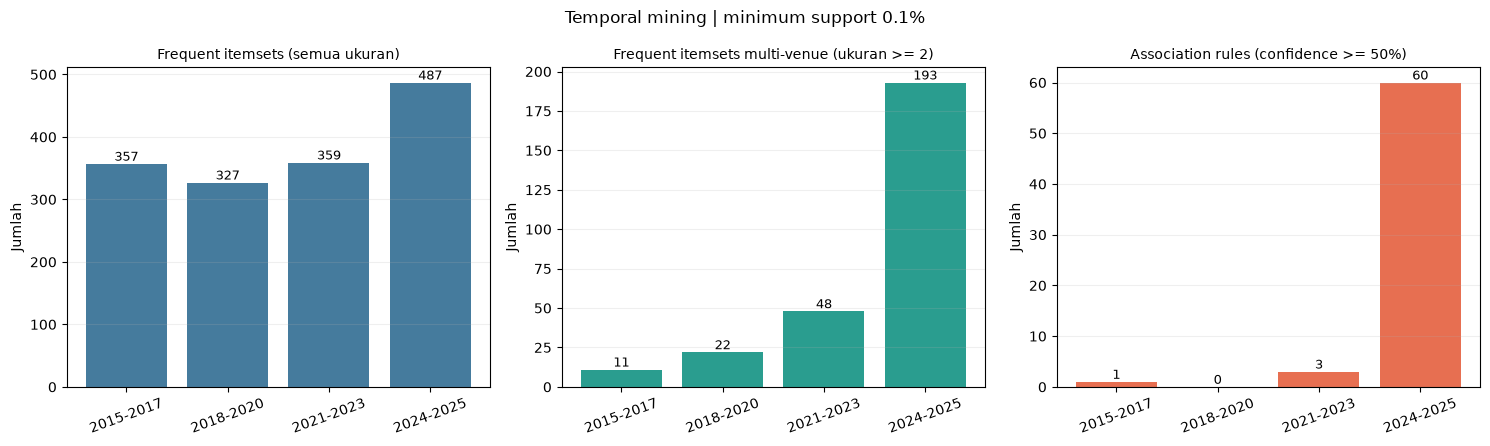

In [22]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4.5))
panels = [
    ('frequent_itemsets', 'Frequent itemsets (semua ukuran)', '#457b9d'),
    ('multi_venue_itemsets', 'Frequent itemsets multi-venue (ukuran >= 2)', '#2a9d8f'),
    ('association_rules', f'Association rules (confidence >= {MIN_CONFIDENCE:.0%})', '#e76f51'),
]
for ax, (column, title, color) in zip(axes, panels):
    ax.bar(summary_df['period'], summary_df[column], color=color)
    ax.set_title(title, fontsize=10)
    ax.set_ylabel('Jumlah')
    ax.tick_params(axis='x', rotation=20)
    ax.grid(axis='y', alpha=0.2)
    for x_pos, value in enumerate(summary_df[column]):
        ax.text(x_pos, value, str(int(value)), ha='center', va='bottom', fontsize=9)
fig.suptitle(f'Temporal mining | minimum support {MIN_SUPPORT:.1%}')
fig.tight_layout()
fig.savefig(FIGURES_DIR / 'bagianE_pattern_counts.png', dpi=160, bbox_inches='tight')
plt.show()

### 3.1 Interpretasi association rules per periode

- **Jumlah rule sangat berbeda antarperiode**: 1 rule pada 2015–2017, 0 rule pada 2018–2020, 3 rule pada 2021–2023, dan 60 rule pada 2024–2025. Pada tiga periode pertama, hampir tidak ada kombinasi venue yang sekaligus memenuhi support 0,1% dan confidence 50%, sedangkan pada periode terakhir terbentuk banyak rule.
- **2015–2017**: satu-satunya rule adalah `ECOC → OFC` (support 0,19%, confidence 51,6%, lift 59,8). Keduanya merupakan konferensi komunikasi optik, sehingga rule ini mencerminkan komunitas riset yang sangat spesifik dan sempit.
- **2018–2020**: tidak ada rule meskipun terdapat pasangan dengan support tertinggi seperti CVPR + ECCV. Hal ini terjadi karena venue besar seperti CVPR memiliki banyak author yang tidak ikut menulis di venue pasangannya, sehingga confidence berada di bawah 50%.
- **2021–2023**: tiga rule berpusat pada venue machine learning dan computer vision (`ICCV + NIPS → CVPR`, `ICLR + ICML → NIPS`, `CVPR + ICLR → NIPS`) dengan lift 20–24.
- **2024–2025**: rule dengan lift tertinggi berasal dari klaster NLP, misalnya `EMNLP + NAACL + NIPS → ACL` (support 0,10%, confidence 72,4%, lift 29,0) dan `ACL + NAACL + NIPS → EMNLP` (confidence 70,8%, lift 25,5). Rule lain mengaitkan venue NLP (ACL, EMNLP, NAACL, COLING) dengan venue machine learning (NIPS, ICML, ICLR). Seluruh rule memiliki lift jauh di atas 1, sehingga kemunculan bersama venue-venue tersebut jauh lebih sering daripada yang diharapkan jika dianggap independen.

## 4. Perbandingan association rules antarperiode (Butir 4)

Perbandingan dilakukan pada tiga tingkat:

1. **Tingkat rule (4.1)**: dua rule dianggap sama jika antecedent dan consequent identik, termasuk arahnya. Nilai support, confidence, dan lift setiap rule disandingkan per periode.
2. **Tingkat itemset (4.2)**: karena jumlah rule pada beberapa periode sangat sedikit, kemiripan kombinasi multi-venue antarperiode juga diukur dengan koefisien Jaccard sebagai pelengkap.
3. **Analisis sensitivitas (4.3)**: ambang confidence diturunkan menjadi 30% sebagai analisis tambahan, hanya untuk memeriksa apakah kesimpulan pada ambang 50% bergantung pada ambang tersebut. Hasil utama tetap memakai confidence 50%.

### 4.1 Perbandingan pada tingkat rule

In [23]:
RULE_KEYS = ['antecedent_key', 'consequent_key']
SUPPORT_COLS = [f'support_{period}' for period in PERIOD_NAMES]
CONFIDENCE_COLS = [f'confidence_{period}' for period in PERIOD_NAMES]
LIFT_COLS = [f'lift_{period}' for period in PERIOD_NAMES]

wide_frames = []
for metric in ['support', 'confidence', 'lift']:
    wide = rules_df.pivot_table(
        index=RULE_KEYS, columns='period', values=metric, aggfunc='first'
    ).reindex(columns=PERIOD_NAMES)
    wide.columns = [f'{metric}_{period}' for period in PERIOD_NAMES]
    wide_frames.append(wide)

comparison_df = pd.concat(wide_frames, axis=1).reset_index()
comparison_df['periods_present'] = comparison_df[SUPPORT_COLS].notna().sum(axis=1)
comparison_df['mean_support'] = comparison_df[SUPPORT_COLS].mean(axis=1)
comparison_df['mean_confidence'] = comparison_df[CONFIDENCE_COLS].mean(axis=1)
comparison_df['mean_lift'] = comparison_df[LIFT_COLS].mean(axis=1)
comparison_df['antecedents'] = comparison_df['antecedent_key'].map(lambda key: format_venues(json.loads(key)))
comparison_df['consequents'] = comparison_df['consequent_key'].map(lambda key: format_venues(json.loads(key)))
comparison_df = comparison_df.sort_values(
    ['periods_present', 'mean_lift', 'mean_support'], ascending=[False, False, False]
).reset_index(drop=True)

persistent_df = comparison_df[comparison_df['periods_present'] >= 2].copy()
comparison_df.to_csv(RESULTS_DIR / 'bagianE_rule_comparison.csv', index=False)
persistent_df.to_csv(RESULTS_DIR / 'bagianE_persistent_rules.csv', index=False)

print(f'Total rule unik (antecedent -> consequent) lintas periode: {len(comparison_df):,}')
presence_counts = (
    comparison_df['periods_present'].value_counts().reindex(range(1, len(PERIOD_NAMES) + 1), fill_value=0)
)
presence_counts.index = [f'muncul di {n} periode' for n in presence_counts.index]
display(presence_counts.rename('jumlah_rule').to_frame())

print('Rule yang lolos ambang pada minimal dua periode:')
display(persistent_df[['antecedents', 'consequents', 'periods_present'] + SUPPORT_COLS + CONFIDENCE_COLS + LIFT_COLS])

Total rule unik (antecedent -> consequent) lintas periode: 61


,jumlah_rule
muncul di 1 periode,58
muncul di 2 periode,3
muncul di 3 periode,0
muncul di 4 periode,0


Rule yang lolos ambang pada minimal dua periode:


,antecedents,consequents,periods_present,support_2015-2017,support_2018-2020,support_2021-2023,support_2024-2025,confidence_2015-2017,confidence_2018-2020,confidence_2021-2023,confidence_2024-2025,lift_2015-2017,lift_2018-2020,lift_2021-2023,lift_2024-2025
0,"iccv, nips",cvpr,2,NaN,NaN,0.001381,0.002318,NaN,NaN,0.580260,0.539370,NaN,NaN,23.846410,15.723860
1,"iclr, icml",nips,2,NaN,NaN,0.001631,0.004368,NaN,NaN,0.635179,0.596121,NaN,NaN,23.154551,12.084302
2,"cvpr, iclr",nips,2,NaN,NaN,0.001062,0.002865,NaN,NaN,0.548123,0.579512,NaN,NaN,19.981028,11.747601


### 4.2 Perbandingan pada tingkat itemset (kombinasi multi-venue)

Koefisien Jaccard dihitung dari himpunan frequent itemsets berukuran ≥ 2 pada setiap pasangan periode: nilai 1 berarti himpunan kombinasi venue identik, sedangkan nilai 0 berarti tidak ada kombinasi yang sama.

Koefisien Jaccard antarperiode untuk frequent itemsets multi-venue:


,2015-2017,2018-2020,2021-2023,2024-2025
2015-2017,1.000,0.435,0.180,0.052
2018-2020,0.435,1.000,0.373,0.108
2021-2023,0.180,0.373,1.000,0.242
2024-2025,0.052,0.108,0.242,1.000


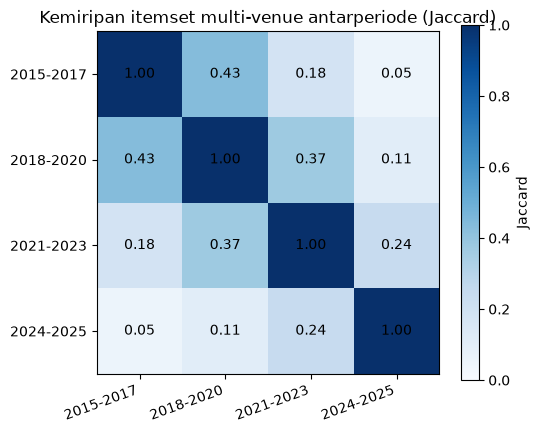

In [24]:
multi_itemsets_df = itemsets_df[itemsets_df['size'] >= 2]
presence = multi_itemsets_df.pivot_table(
    index='itemset_codes', columns='period', values='support', aggfunc='first'
).reindex(columns=PERIOD_NAMES)
presence_bool = presence.notna()

jaccard = pd.DataFrame(index=PERIOD_NAMES, columns=PERIOD_NAMES, dtype=float)
for first in PERIOD_NAMES:
    for second in PERIOD_NAMES:
        intersection = (presence_bool[first] & presence_bool[second]).sum()
        union = (presence_bool[first] | presence_bool[second]).sum()
        jaccard.loc[first, second] = intersection / union if union else np.nan

print('Koefisien Jaccard antarperiode untuk frequent itemsets multi-venue:')
display(jaccard.round(3))
jaccard.to_csv(RESULTS_DIR / 'bagianE_itemset_jaccard.csv')

fig, ax = plt.subplots(figsize=(5.5, 4.5))
image = ax.imshow(jaccard.to_numpy(dtype=float), cmap='Blues', vmin=0, vmax=1)
ax.set_xticks(range(len(PERIOD_NAMES)), labels=PERIOD_NAMES, rotation=20, ha='right')
ax.set_yticks(range(len(PERIOD_NAMES)), labels=PERIOD_NAMES)
for row_index in range(len(PERIOD_NAMES)):
    for col_index in range(len(PERIOD_NAMES)):
        ax.text(col_index, row_index, f'{jaccard.iloc[row_index, col_index]:.2f}', ha='center', va='center')
ax.set_title('Kemiripan itemset multi-venue antarperiode (Jaccard)')
fig.colorbar(image, ax=ax, label='Jaccard')
fig.tight_layout()
fig.savefig(FIGURES_DIR / 'bagianE_itemset_overlap.png', dpi=160, bbox_inches='tight')
plt.show()

### 4.3 Analisis sensitivitas terhadap ambang confidence (tambahan)

Rule pada tiga periode pertama sangat sedikit sehingga perbandingan pada confidence 50% bersifat terbatas. Analisis tambahan ini membangkitkan ulang rule dari frequent itemsets yang sama dengan confidence minimum 30% untuk melihat apakah pola yang bertahan antarperiode lebih banyak teridentifikasi saat ambang dilonggarkan. Hasil ini hanya pelengkap dan tidak menggantikan hasil utama.

In [25]:
sensitivity_rows = []
for period_name in PERIOD_NAMES:
    relaxed_rules = generate_rules(
        freq_by_period[period_name],
        total_transactions=TX_COUNTS[period_name],
        min_confidence=SENSITIVITY_CONFIDENCE,
    )
    for rule in relaxed_rules.itertuples(index=False):
        sensitivity_rows.append({
            'period': period_name,
            'antecedent_key': json.dumps(sorted(rule.antecedents), ensure_ascii=False),
            'consequent_key': json.dumps(sorted(rule.consequents), ensure_ascii=False),
            'antecedents': format_venues(rule.antecedents),
            'consequents': format_venues(rule.consequents),
            'support': rule.support,
            'confidence': rule.confidence,
            'lift': rule.lift,
        })

sensitivity_df = pd.DataFrame(sensitivity_rows)
sensitivity_df.to_csv(RESULTS_DIR / 'bagianE_rule_sensitivity_conf30.csv', index=False)

relaxed_counts = sensitivity_df.groupby('period').size().reindex(PERIOD_NAMES, fill_value=0)
overview = pd.DataFrame({
    'rules_confidence_50': summary_df.set_index('period')['association_rules'],
    f'rules_confidence_{int(SENSITIVITY_CONFIDENCE * 100)}': relaxed_counts,
})
print('Jumlah rule per periode pada dua ambang confidence:')
display(overview)

relaxed_cmp = sensitivity_df.groupby(RULE_KEYS + ['antecedents', 'consequents'], as_index=False).agg(
    periods_present=('period', 'nunique'),
    mean_support=('support', 'mean'),
    mean_confidence=('confidence', 'mean'),
    mean_lift=('lift', 'mean'),
)
print('Distribusi jumlah periode kemunculan rule (confidence 30%):')
display(relaxed_cmp['periods_present'].value_counts().sort_index().rename('jumlah_rule').to_frame())

print('Rule dengan kemunculan di minimal tiga periode (confidence 30%):')
display(
    relaxed_cmp[relaxed_cmp['periods_present'] >= 3]
    .sort_values(['periods_present', 'mean_lift'], ascending=[False, False])
    [['antecedents', 'consequents', 'periods_present', 'mean_support', 'mean_confidence', 'mean_lift']]
    .head(15)
    .reset_index(drop=True)
)

Jumlah rule per periode pada dua ambang confidence:


,rules_confidence_50,rules_confidence_30
period,,
2015-2017,1,2
2018-2020,0,6
2021-2023,3,14
2024-2025,60,158


Distribusi jumlah periode kemunculan rule (confidence 30%):


,jumlah_rule
periods_present,
1,145
2,8
3,5
4,1


Rule dengan kemunculan di minimal tiga periode (confidence 30%):


,antecedents,consequents,periods_present,mean_support,mean_confidence,mean_lift
0,iccv,cvpr,4,0.003032,0.347937,22.182874
1,ecoc,ofc,3,0.001546,0.476803,59.998795
2,acl,emnlp,3,0.004802,0.331086,25.213372
3,icml,nips,3,0.005606,0.354997,15.332977
4,iclr,nips,3,0.005479,0.346102,14.678082
5,eccv,cvpr,3,0.003084,0.318404,14.010963


### 4.4 Interpretasi perbandingan antarperiode

- Pada ambang utama (support 0,1% dan confidence 50%), total terdapat 61 rule unik. Hanya 3 rule yang muncul pada lebih dari satu periode, yaitu `ICCV + NIPS → CVPR`, `ICLR + ICML → NIPS`, dan `CVPR + ICLR → NIPS`; ketiganya muncul pada 2021–2023 dan 2024–2025. Tidak ada rule yang lolos ambang di keempat periode, dan 58 rule lainnya hanya muncul pada satu periode (1 rule pada 2015–2017 dan 57 rule pada 2024–2025).
- Tabel Jaccard pada bagian 4.2 menunjukkan seberapa besar himpunan kombinasi multi-venue pada satu periode juga ditemukan pada periode lain. Himpunan kombinasi pada 2024–2025 jauh lebih besar daripada periode lain (193 itemset multi-venue), sehingga memuat banyak kombinasi yang tidak ditemukan pada periode awal; tingkat kemiripan antarperiode yang tepat dibaca langsung dari nilai Jaccard pada tabel tersebut.
- Hasil analisis sensitivitas (4.3) memperlihatkan jumlah rule yang dapat ditelusuri antarperiode ketika ambang confidence dilonggarkan. Kesimpulan arah perubahan (jumlah rule meningkat tajam pada periode terbaru) tetap perlu dibaca bersama tabel tersebut, namun hasil utama tidak bergantung pada ambang tambahan ini.

## 5. Pola yang bertahan dan pola yang berubah (Butir 5)

Identifikasi pola dilakukan pada dua tingkat. Pada tingkat rule (5.1), pola yang bertahan adalah rule yang lolos ambang di lebih dari satu periode. Pada tingkat itemset (5.2 dan 5.3), setiap kombinasi multi-venue diklasifikasikan menurut urutan periode kemunculannya: bertahan di semua periode, muncul kemudian dan bertahan, hanya muncul di periode awal, dan seterusnya. Selanjutnya, bagian 5.4 menelusuri mengapa rule yang hanya muncul pada satu periode tidak lolos pada periode lain, apakah karena support di bawah ambang atau karena confidence turun di bawah 50%.

### 5.1 Rule yang bertahan antarperiode

Rule yang muncul pada semua periode: 0
Rule yang muncul pada minimal dua periode: 3
Rule yang hanya muncul pada satu periode: 58
Perubahan support, confidence, dan lift pada rule yang bertahan:


,rule,support_2015-2017,support_2018-2020,support_2021-2023,support_2024-2025,confidence_2015-2017,confidence_2018-2020,confidence_2021-2023,confidence_2024-2025,lift_2015-2017,lift_2018-2020,lift_2021-2023,lift_2024-2025
0,"iccv, nips -> cvpr",NaN,NaN,0.0014,0.0023,NaN,NaN,0.5803,0.5394,NaN,NaN,23.8464,15.7239
1,"iclr, icml -> nips",NaN,NaN,0.0016,0.0044,NaN,NaN,0.6352,0.5961,NaN,NaN,23.1546,12.0843
2,"cvpr, iclr -> nips",NaN,NaN,0.0011,0.0029,NaN,NaN,0.5481,0.5795,NaN,NaN,19.9810,11.7476


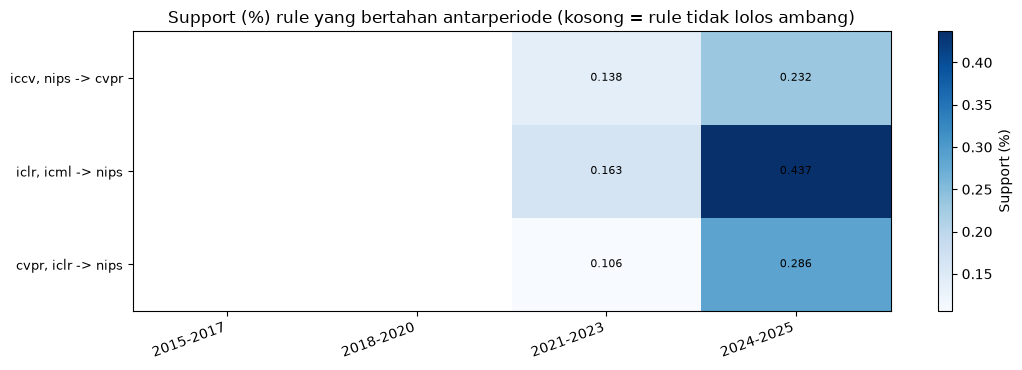

In [26]:
all_period_rules = comparison_df[comparison_df['periods_present'] == len(PERIOD_NAMES)]
single_period_rules = comparison_df[comparison_df['periods_present'] == 1]
print(f'Rule yang muncul pada semua periode: {len(all_period_rules):,}')
print(f'Rule yang muncul pada minimal dua periode: {len(persistent_df):,}')
print(f'Rule yang hanya muncul pada satu periode: {len(single_period_rules):,}')

if persistent_df.empty:
    print('Tidak ada rule yang bertahan pada minimal dua periode.')
else:
    persistent_view = persistent_df.copy()
    persistent_view['rule'] = persistent_view['antecedents'] + ' -> ' + persistent_view['consequents']
    print('Perubahan support, confidence, dan lift pada rule yang bertahan:')
    display(persistent_view[['rule'] + SUPPORT_COLS + CONFIDENCE_COLS + LIFT_COLS].round(4))

fig, ax = plt.subplots(figsize=(11, max(3.5, 0.6 * max(1, len(persistent_df)) + 2)))
if persistent_df.empty:
    ax.text(0.5, 0.5, 'Tidak ada rule yang bertahan pada minimal dua periode', ha='center', va='center')
    ax.set_axis_off()
else:
    selected = persistent_df.head(10)
    matrix = selected[SUPPORT_COLS].to_numpy(dtype=float) * 100
    image = ax.imshow(np.ma.masked_invalid(matrix), aspect='auto', cmap='Blues')
    labels = ['{} -> {}'.format(row.antecedents, row.consequents)[:90] for row in selected.itertuples(index=False)]
    ax.set_yticks(range(len(labels)), labels=labels, fontsize=9)
    ax.set_xticks(range(len(PERIOD_NAMES)), labels=PERIOD_NAMES, rotation=20, ha='right')
    for row_index in range(matrix.shape[0]):
        for col_index in range(matrix.shape[1]):
            if not np.isnan(matrix[row_index, col_index]):
                ax.text(col_index, row_index, f'{matrix[row_index, col_index]:.3f}', ha='center', va='center', fontsize=8)
    ax.set_title('Support (%) rule yang bertahan antarperiode (kosong = rule tidak lolos ambang)')
    fig.colorbar(image, ax=ax, label='Support (%)')
fig.tight_layout()
fig.savefig(FIGURES_DIR / 'bagianE_persistent_rule_support.png', dpi=160, bbox_inches='tight')
plt.show()

### 5.2 Status kemunculan kombinasi multi-venue antarperiode

Setiap frequent itemset berukuran ≥ 2 diberi status berdasarkan periode tempat itemset tersebut lolos ambang support.

In [27]:
def classify_status(flags):
    present = [period for period in PERIOD_NAMES if flags[period]]
    count = len(present)
    if count == len(PERIOD_NAMES):
        return 'Bertahan di semua periode'
    if present == PERIOD_NAMES[-count:]:
        return 'Baru muncul pada periode terbaru' if count == 1 else 'Muncul kemudian dan bertahan hingga periode terbaru'
    if present == PERIOD_NAMES[:count]:
        return 'Hanya pada periode awal' if count == 1 else 'Muncul di periode awal lalu menghilang'
    return 'Muncul sementara (tidak berurutan)'


status_table = presence.copy()
status_table.columns = [f'support_{period}' for period in PERIOD_NAMES]
status_table['status'] = presence_bool.apply(classify_status, axis=1)
status_table['itemset'] = [', '.join(json.loads(key)) for key in status_table.index]
status_table['max_support'] = status_table[SUPPORT_COLS].max(axis=1)
status_table = status_table.sort_values('max_support', ascending=False)
status_table.reset_index(drop=True).to_csv(RESULTS_DIR / 'bagianE_itemset_status.csv', index=False)

STATUS_ORDER = [
    'Bertahan di semua periode',
    'Muncul kemudian dan bertahan hingga periode terbaru',
    'Baru muncul pada periode terbaru',
    'Muncul sementara (tidak berurutan)',
    'Muncul di periode awal lalu menghilang',
    'Hanya pada periode awal',
]
status_counts = status_table['status'].value_counts().reindex(STATUS_ORDER, fill_value=0)
print(f'Total kombinasi multi-venue unik lintas periode: {len(status_table):,}')
display(status_counts.rename('jumlah_itemset').to_frame())

for status in STATUS_ORDER:
    subset = status_table[status_table['status'] == status]
    if subset.empty:
        continue
    print(f'{status}: contoh kombinasi dengan support tertinggi')
    display(subset[['itemset'] + SUPPORT_COLS].head(8).reset_index(drop=True))

Total kombinasi multi-venue unik lintas periode: 194


,jumlah_itemset
status,
Bertahan di semua periode,8
Muncul kemudian dan bertahan hingga periode terbaru,39
Baru muncul pada periode terbaru,142
Muncul sementara (tidak berurutan),4
Muncul di periode awal lalu menghilang,1
Hanya pada periode awal,0


Bertahan di semua periode: contoh kombinasi dengan support tertinggi


,itemset,support_2015-2017,support_2018-2020,support_2021-2023,support_2024-2025
0,"icml, nips",0.001011,0.002416,0.004541,0.009863
1,"cvpr, iccv",0.001330,0.001288,0.004227,0.005285
2,"icra, iros",0.001930,0.002049,0.002212,0.003228
3,"globecom, icc",0.003207,0.002522,0.002678,0.002493
4,"aaai, ijcai",0.001573,0.002021,0.001889,0.003107
5,"icassp, interspeech",0.001406,0.001801,0.002548,0.002397
6,"globecom, vtc",0.001675,0.001120,0.001249,0.001424
7,"icc, vtc",0.001672,0.001106,0.001034,0.001337


Muncul kemudian dan bertahan hingga periode terbaru: contoh kombinasi dengan support tertinggi


,itemset,support_2015-2017,support_2018-2020,support_2021-2023,support_2024-2025
0,"iclr, nips",NaN,0.001778,0.004210,0.010448
1,"cvpr, nips",NaN,0.001659,0.004055,0.008324
2,"acl, emnlp",NaN,0.002011,0.004328,0.008066
3,"iclr, icml",NaN,0.001254,0.002567,0.007328
4,"aaai, nips",NaN,0.001543,0.003222,0.007090
5,"emnlp, nips",NaN,NaN,0.001769,0.005748
6,"acl, nips",NaN,NaN,0.001611,0.005699
7,"aaai, cvpr",NaN,0.001644,0.002595,0.005223


... (2 outputs left out)

Muncul sementara (tidak berurutan): contoh kombinasi dengan support tertinggi


,itemset,support_2015-2017,support_2018-2020,support_2021-2023,support_2024-2025
0,"ecoc, ofc",0.001867,0.001442,NaN,0.001331
1,"aaai, eccv",NaN,0.001007,NaN,0.001827
2,"globecom, wcnc",NaN,0.001002,NaN,0.001311
3,"icc, wcnc",0.001037,NaN,NaN,0.001126


Muncul di periode awal lalu menghilang: contoh kombinasi dengan support tertinggi


,itemset,support_2015-2017,support_2018-2020,support_2021-2023,support_2024-2025
0,"amcc, cdc",0.002039,0.001412,0.001115,NaN


### 5.3 Tren support pada kombinasi yang bertahan di semua periode

Kombinasi multi-venue yang lolos ambang di keempat periode: 8


,itemset,support_2015-2017,support_2018-2020,support_2021-2023,support_2024-2025,rasio_terbaru_vs_awal
0,"icml, nips",0.00101,0.00242,0.00454,0.00986,9.75775
1,"cvpr, iccv",0.00133,0.00129,0.00423,0.00529,3.97482
2,"globecom, icc",0.00321,0.00252,0.00268,0.00249,0.77722
3,"icra, iros",0.00193,0.00205,0.00221,0.00323,1.67207
4,"aaai, ijcai",0.00157,0.00202,0.00189,0.00311,1.97587
5,"icassp, interspeech",0.00141,0.00180,0.00255,0.00240,1.70514
6,"globecom, vtc",0.00167,0.00112,0.00125,0.00142,0.85067
7,"icc, vtc",0.00167,0.00111,0.00103,0.00134,0.79917


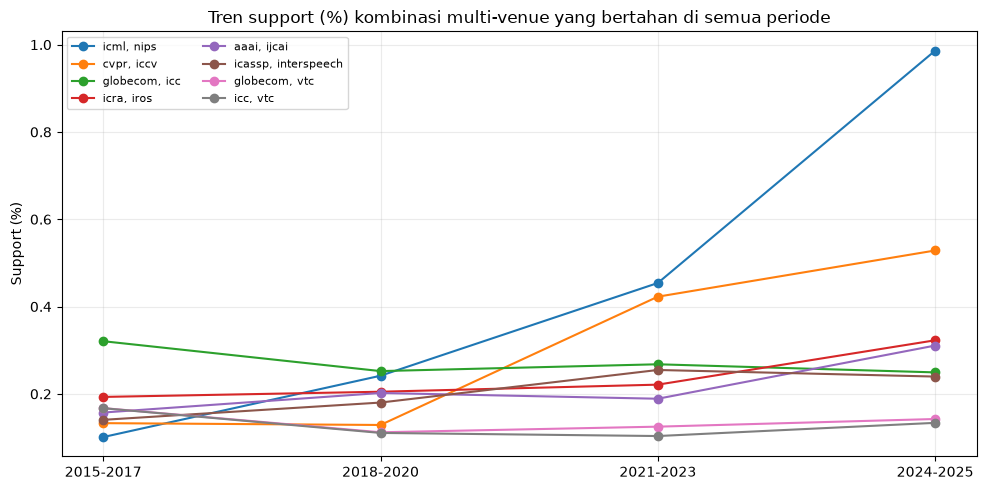

In [28]:
stable_df = status_table[status_table['status'] == 'Bertahan di semua periode'].copy()
stable_df['mean_support'] = stable_df[SUPPORT_COLS].mean(axis=1)
stable_df['rasio_terbaru_vs_awal'] = stable_df[SUPPORT_COLS[-1]] / stable_df[SUPPORT_COLS[0]]
stable_df = stable_df.sort_values('mean_support', ascending=False)
stable_df.reset_index(drop=True).to_csv(RESULTS_DIR / 'bagianE_stable_itemsets.csv', index=False)

print(f'Kombinasi multi-venue yang lolos ambang di keempat periode: {len(stable_df):,}')
display((stable_df[['itemset'] + SUPPORT_COLS + ['rasio_terbaru_vs_awal']].head(15)).reset_index(drop=True).round(5))

fig, ax = plt.subplots(figsize=(10, 5))
if stable_df.empty:
    ax.text(0.5, 0.5, 'Tidak ada kombinasi yang bertahan di semua periode', ha='center', va='center')
    ax.set_axis_off()
else:
    top_stable = stable_df.head(8)
    for _, row in top_stable.iterrows():
        ax.plot(PERIOD_NAMES, row[SUPPORT_COLS].astype(float).to_numpy() * 100, marker='o', label=row['itemset'])
    ax.set_title('Tren support (%) kombinasi multi-venue yang bertahan di semua periode')
    ax.set_ylabel('Support (%)')
    ax.grid(alpha=0.25)
    ax.legend(fontsize=8, ncol=2)
fig.tight_layout()
fig.savefig(FIGURES_DIR / 'bagianE_persistent_itemset_trend.png', dpi=160, bbox_inches='tight')
plt.show()

### 5.4 Diagnostik rule yang hanya muncul pada satu periode

Untuk sepuluh rule spesifik periode dengan lift tertinggi, support dan confidence dihitung ulang pada setiap periode dari frequent itemsets yang tersedia. Nilai kosong (NaN) berarti itemset gabungan atau antecedent/consequent-nya tidak lolos ambang support 0,1% pada periode tersebut, sehingga rule tidak dapat dievaluasi. Nilai confidence di bawah 50% menunjukkan bahwa itemset masih frequent tetapi kekuatan implikasinya melemah.

In [29]:
def rule_metrics(period, antecedents, consequents):
    lookup = freq_lookup[period]
    antecedent_set = frozenset(antecedents)
    consequent_set = frozenset(consequents)
    union_count = lookup.get(antecedent_set | consequent_set)
    antecedent_count = lookup.get(antecedent_set)
    consequent_count = lookup.get(consequent_set)
    if union_count is None or antecedent_count is None or consequent_count is None:
        return np.nan, np.nan, np.nan
    total = TX_COUNTS[period]
    confidence = union_count / antecedent_count
    return union_count / total, confidence, confidence / (consequent_count / total)


specific_keys = comparison_df.loc[comparison_df['periods_present'] == 1, RULE_KEYS]
specific_rules = (
    rules_df.merge(specific_keys, on=RULE_KEYS)
    .sort_values('lift', ascending=False)
    .head(10)
)

diagnostic_rows = []
for rule in specific_rules.itertuples(index=False):
    antecedents = json.loads(rule.antecedent_key)
    consequents = json.loads(rule.consequent_key)
    row = {
        'rule': '{} -> {}'.format(', '.join(antecedents), ', '.join(consequents)),
        'periode_lolos': rule.period,
    }
    for period in PERIOD_NAMES:
        support_value, confidence_value, _ = rule_metrics(period, antecedents, consequents)
        row[f'support_{period}'] = support_value
        row[f'confidence_{period}'] = confidence_value
    diagnostic_rows.append(row)

diagnostic_df = pd.DataFrame(diagnostic_rows)
diagnostic_df.to_csv(RESULTS_DIR / 'bagianE_specific_rule_diagnostics.csv', index=False)
display(diagnostic_df.round(4))

,rule,periode_lolos,support_2015-2017,confidence_2015-2017,support_2018-2020,confidence_2018-2020,support_2021-2023,confidence_2021-2023,support_2024-2025,confidence_2024-2025
0,ecoc -> ofc,2015-2017,0.0019,0.5159,0.0014,0.4724,NaN,NaN,0.0013,0.4421
1,"emnlp, naacl, nips -> acl",2024-2025,NaN,NaN,NaN,NaN,NaN,NaN,0.0010,0.7243
2,"acl, naacl, nips -> emnlp",2024-2025,NaN,NaN,NaN,NaN,NaN,NaN,0.0010,0.7078
3,"emnlp, iclr, nips -> acl",2024-2025,NaN,NaN,NaN,NaN,NaN,NaN,0.0014,0.5937
4,"iclr, naacl -> acl",2024-2025,NaN,NaN,NaN,NaN,NaN,NaN,0.0012,0.5832
5,"naacl, nips -> acl",2024-2025,NaN,NaN,NaN,NaN,NaN,NaN,0.0014,0.5724
6,"emnlp, naacl -> acl",2024-2025,NaN,NaN,NaN,NaN,NaN,NaN,0.0023,0.5683
7,"coling, emnlp -> acl",2024-2025,NaN,NaN,NaN,NaN,NaN,NaN,0.0016,0.5640
8,"emnlp, icml, nips -> acl",2024-2025,NaN,NaN,NaN,NaN,NaN,NaN,0.0011,0.5625
9,"acl, icml, nips -> iclr",2024-2025,NaN,NaN,NaN,NaN,NaN,NaN,0.0012,0.6388


### 5.5 Interpretasi pola yang bertahan dan berubah

**Pola yang bertahan.**

- Tiga rule yang bertahan pada 2021–2023 dan 2024–2025 (`ICCV + NIPS → CVPR`, `ICLR + ICML → NIPS`, `CVPR + ICLR → NIPS`) memperlihatkan kecenderungan yang sama: support naik pada periode terakhir (misalnya `ICLR + ICML → NIPS` naik dari 0,163% menjadi 0,437%), sedangkan confidence relatif stabil di kisaran 54–60%. Nilai lift justru turun menjadi sekitar 12–16 dari semula 20–24, karena support consequent (khususnya NIPS, dari 2,74% menjadi 4,93%) tumbuh lebih cepat daripada confidence rule. Artinya, asosiasi antar venue ML/CV tetap kuat, tetapi keistimewaannya relatif terhadap baseline berkurang seiring NIPS makin banyak dipublikasikan oleh banyak author.
- Pada tingkat itemset, tabel status pada 5.2 dan 5.3 memperlihatkan pasangan venue yang konsisten muncul di keempat periode, seperti pasangan telekomunikasi (GLOBECOM + ICC) dan pasangan pemrosesan sinyal/suara (ICASSP + INTERSPEECH). Pasangan semacam ini membentuk kebiasaan publikasi yang stabil, walaupun confidence-nya tidak cukup tinggi untuk membentuk rule.

**Pola yang berubah.**

- Satu-satunya rule 2015–2017, `ECOC → OFC`, tidak ditemukan sebagai rule pada periode lain. Tabel diagnostik 5.4 menunjukkan apakah penyebabnya adalah support yang turun di bawah ambang atau confidence yang melemah.
- Lima puluh tujuh rule yang khusus muncul pada 2024–2025 didominasi kombinasi venue NLP (ACL, EMNLP, NAACL, COLING) dengan venue machine learning (NIPS, ICML, ICLR). Tabel diagnostik 5.4 menunjukkan, untuk setiap rule, apakah itemset gabungannya sudah memenuhi ambang support pada periode sebelumnya (nilai terisi) atau belum (NaN), sehingga dapat dibedakan rule yang baru muncul karena kombinasinya baru cukup sering terjadi dari rule yang sebelumnya sudah ada tetapi confidence-nya masih di bawah 50%.
- Kombinasi multi-venue yang diklasifikasikan sebagai muncul kemudian atau baru muncul pada periode terbaru (bagian 5.2) menunjukkan tumbuhnya pola kolaborasi publikasi lintas subbidang yang tidak terlihat pada periode awal.

## 6. Kemungkinan perubahan tren publikasi (Butir 6)

Bagian ini merangkum bukti kuantitatif untuk menjelaskan kemungkinan perubahan tren. Pertama, indikator ringkas tiap periode dibandingkan. Kedua, support pasangan venue kunci dikelompokkan menurut area riset untuk melihat arah perubahan di setiap area. Ketiga, support venue tunggal utama dibandingkan antarperiode. Nilai kosong (NaN) berarti itemset tidak lolos ambang support 0,1% pada periode tersebut, sehingga bukan berarti support-nya nol.

6.1 Indikator ringkas per periode:


,transaksi,frequent_itemsets,itemset_multi_venue,persen_multi_venue,rules,lift_maks,venue_teratas,support_venue_teratas_%,pasangan_teratas,support_pasangan_teratas_%
period,,,,,,,,,,
2015-2017,922044,357,11,3.081,1,59.765,embc,1.875,"globecom, icc",0.321
2018-2020,1080818,327,22,6.728,0,NaN,igarss,1.776,"cvpr, eccv",0.276
2021-2023,1195896,359,48,13.370,3,23.846,nips,2.743,"icml, nips",0.454
2024-2025,886637,487,193,39.630,60,28.967,nips,4.933,"iclr, nips",1.045


6.2 Support (%) pasangan venue kunci per periode:


,area,pasangan,2015-2017,2018-2020,2021-2023,2024-2025
0,Machine learning,icml + nips,0.1011,0.2416,0.4541,0.9863
1,Machine learning,iclr + nips,NaN,0.1778,0.4210,1.0448
2,Machine learning,iclr + icml,NaN,0.1254,0.2567,0.7328
3,Computer vision,cvpr + iccv,0.1330,0.1288,0.4227,0.5285
4,Computer vision,cvpr + eccv,NaN,0.2761,0.2157,0.4333
5,Computer vision,cvpr + nips,NaN,0.1659,0.4055,0.8324
6,NLP,acl + emnlp,NaN,0.2011,0.4328,0.8066
7,NLP,emnlp + nips,NaN,NaN,0.1769,0.5748
8,NLP,acl + nips,NaN,NaN,0.1611,0.5699
9,AI umum,aaai + ijcai,0.1573,0.2021,0.1889,0.3107


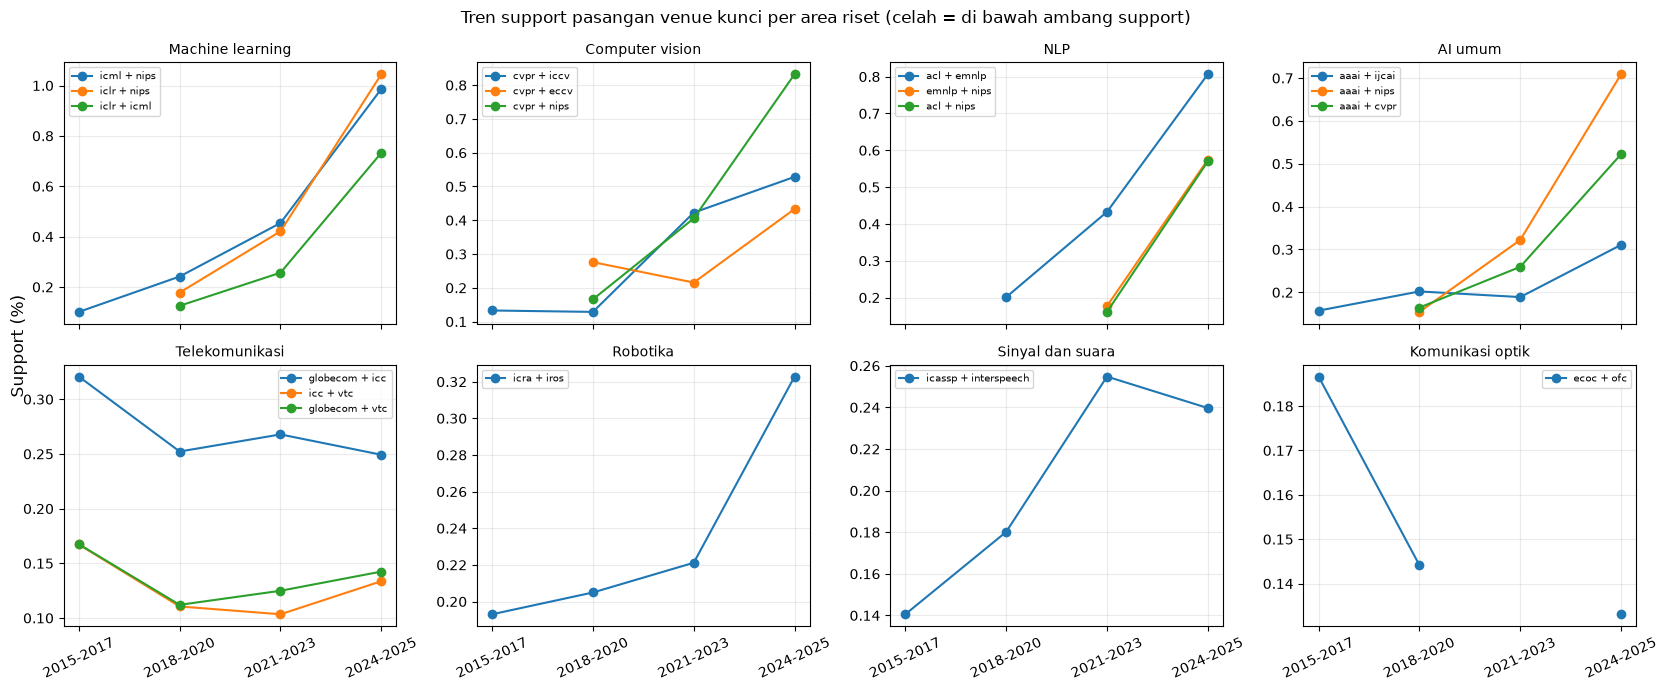

6.3 Support (%) venue tunggal utama per periode:


,venue,2015-2017,2018-2020,2021-2023,2024-2025
0,nips,0.529,1.325,2.743,4.933
1,cvpr,0.848,1.593,2.433,3.430
2,aaai,0.790,1.402,1.826,2.919
3,iclr,0.101,0.573,1.160,2.861
4,icml,0.343,0.721,1.243,2.707
5,acl,0.351,0.607,1.276,2.500
6,emnlp,0.310,0.808,1.476,2.775
7,iccv,0.380,0.336,1.205,1.721
8,icassp,1.076,1.310,1.769,2.461
9,igarss,1.495,1.776,1.671,1.012


In [30]:
def support_of(period, venues):
    count = freq_lookup[period].get(frozenset(venues))
    return count / TX_COUNTS[period] if count is not None else np.nan


# 6.1 Indikator ringkas per periode
top_single = itemsets_df[itemsets_df['size'] == 1].groupby('period').head(1).set_index('period')
top_pair = itemsets_df[itemsets_df['size'] == 2].groupby('period').head(1).set_index('period')
max_lift = rules_df.groupby('period')['lift'].max().reindex(PERIOD_NAMES)

indicator_df = pd.DataFrame({
    'transaksi': summary_df.set_index('period')['transactions'],
    'frequent_itemsets': summary_df.set_index('period')['frequent_itemsets'],
    'itemset_multi_venue': summary_df.set_index('period')['multi_venue_itemsets'],
    'persen_multi_venue': summary_df.set_index('period')['multi_venue_itemsets']
                          / summary_df.set_index('period')['frequent_itemsets'] * 100,
    'rules': summary_df.set_index('period')['association_rules'],
    'lift_maks': max_lift,
    'venue_teratas': top_single['itemset'],
    'support_venue_teratas_%': top_single['support'] * 100,
    'pasangan_teratas': top_pair['itemset'],
    'support_pasangan_teratas_%': top_pair['support'] * 100,
}).reindex(PERIOD_NAMES)
indicator_df.to_csv(RESULTS_DIR / 'bagianE_period_indicators.csv')
print('6.1 Indikator ringkas per periode:')
display(indicator_df.round(3))

# 6.2 Support pasangan venue kunci menurut area riset
AREA_PAIRS = {
    'Machine learning': [('icml', 'nips'), ('iclr', 'nips'), ('iclr', 'icml')],
    'Computer vision': [('cvpr', 'iccv'), ('cvpr', 'eccv'), ('cvpr', 'nips')],
    'NLP': [('acl', 'emnlp'), ('emnlp', 'nips'), ('acl', 'nips')],
    'AI umum': [('aaai', 'ijcai'), ('aaai', 'nips'), ('aaai', 'cvpr')],
    'Telekomunikasi': [('globecom', 'icc'), ('icc', 'vtc'), ('globecom', 'vtc')],
    'Robotika': [('icra', 'iros')],
    'Sinyal dan suara': [('icassp', 'interspeech')],
    'Komunikasi optik': [('ecoc', 'ofc')],
}
pair_rows = []
for area, pairs in AREA_PAIRS.items():
    for pair in pairs:
        row = {'area': area, 'pasangan': ' + '.join(pair)}
        for period in PERIOD_NAMES:
            row[period] = support_of(period, pair) * 100
        pair_rows.append(row)
pair_df = pd.DataFrame(pair_rows)
pair_df.to_csv(RESULTS_DIR / 'bagianE_key_pair_support.csv', index=False)
print('6.2 Support (%) pasangan venue kunci per periode:')
display(pair_df.round(4))

areas = list(AREA_PAIRS.keys())
fig, axes = plt.subplots(2, 4, figsize=(17, 7), sharex=True)
for ax, area in zip(axes.flat, areas):
    group = pair_df[pair_df['area'] == area]
    for _, row in group.iterrows():
        ax.plot(PERIOD_NAMES, row[PERIOD_NAMES].astype(float).to_numpy(), marker='o', label=row['pasangan'])
    ax.set_title(area, fontsize=10)
    ax.grid(alpha=0.25)
    ax.legend(fontsize=7)
    ax.tick_params(axis='x', rotation=25)
for ax in list(axes.flat)[len(areas):]:
    ax.set_axis_off()
fig.supylabel('Support (%)')
fig.suptitle('Tren support pasangan venue kunci per area riset (celah = di bawah ambang support)')
fig.tight_layout()
fig.savefig(FIGURES_DIR / 'bagianE_key_pair_trend.png', dpi=160, bbox_inches='tight')
plt.show()

# 6.3 Support venue tunggal utama
KEY_VENUES = ['nips', 'cvpr', 'aaai', 'iclr', 'icml', 'acl', 'emnlp', 'iccv', 'icassp', 'igarss', 'embc', 'icc', 'globecom']
venue_rows = []
for venue in KEY_VENUES:
    row = {'venue': venue}
    for period in PERIOD_NAMES:
        row[period] = support_of(period, (venue,)) * 100
    venue_rows.append(row)
venue_df = pd.DataFrame(venue_rows)
venue_df.to_csv(RESULTS_DIR / 'bagianE_key_venue_support.csv', index=False)
print('6.3 Support (%) venue tunggal utama per periode:')
display(venue_df.round(3))

### 6.4 Interpretasi kemungkinan perubahan tren publikasi

Berdasarkan hasil eksperimen pada bagian 2 sampai 6, beberapa kemungkinan perubahan tren dapat diidentifikasi. Seluruh penjelasan berikut bersifat indikasi asosiatif dari data publikasi, bukan bukti hubungan sebab-akibat.

1. **Pergeseran pusat aktivitas dari venue rekayasa dan penginderaan jauh ke venue machine learning.** Venue tunggal dengan support tertinggi berubah dari EMBC, IGARSS, HCI, ICC, dan GLOBECOM pada 2015–2017 menjadi NIPS, CVPR, AAAI, ICLR, EMNLP, dan ICML pada 2024–2025. Support NIPS naik dari 2,74% pada 2021–2023 menjadi 4,93% pada 2024–2025. Hal ini konsisten dengan meningkatnya volume publikasi deep learning dan AI pada periode terbaru.
2. **Meningkatnya kebiasaan mempublikasikan di beberapa venue sekaligus pada tahun yang sama.** Kombinasi multi-venue yang lolos ambang naik dari 11 menjadi 22, 48, dan 193, dan pasangan teratas meningkat dari support 0,32% (GLOBECOM + ICC, 2015–2017) menjadi 1,04% (ICLR + NIPS, 2024–2025). Kenaikan ini terjadi walaupun jumlah transaksi periode terakhir lebih kecil, sehingga lebih mungkin mencerminkan perubahan perilaku publikasi daripada efek ukuran data. Penjelasan yang masuk akal antara lain meningkatnya jumlah paper per author per tahun, kolaborasi tim besar, dan konsentrasi riset pada sejumlah venue utama.
3. **Menyatunya klaster NLP dan machine learning.** Pada 2024–2025 rule dengan lift tertinggi menghubungkan venue NLP (ACL, EMNLP, NAACL, COLING) dengan venue machine learning (NIPS, ICML, ICLR). Rule dengan confidence di atas 70% seperti `EMNLP + NAACL + NIPS → ACL` menunjukkan bahwa author yang aktif di beberapa venue tersebut hampir selalu juga menulis di ACL pada tahun yang sama. Hal ini dapat mencerminkan integrasi metode machine learning ke dalam riset bahasa alami.
4. **Asosiasi yang kuat namun makin tidak eksklusif.** Pada tiga rule yang bertahan (ML dan computer vision), confidence tetap stabil tetapi lift menurun karena support consequent tumbuh lebih cepat. Dengan demikian, kedekatan antar-venue besar tetap ada, namun kemunculan bersamanya semakin tidak istimewa dibandingkan baseline karena venue-venue tersebut semakin besar.
5. **Komunitas niche cenderung stabil dan tidak ikut membentuk rule baru.** Rule `ECOC → OFC` pada 2015–2017 memiliki lift tertinggi di seluruh eksperimen (59,8), yang wajar untuk dua venue yang sangat spesifik pada komunitas komunikasi optik. Pasangan telekomunikasi (GLOBECOM + ICC) dan sinyal/suara (ICASSP + INTERSPEECH) tetap muncul di semua periode, tetapi pertumbuhan support-nya jauh lebih kecil daripada pasangan machine learning, sehingga dalam konteks ambang yang sama kontribusi relatifnya mengecil.
6. **Pertimbangan penafsiran.** Periode 2024–2025 hanya mencakup dua tahun, dan data tahun terakhir dapat belum sepenuhnya terindeks. Ambang support relatif yang sama berarti ambang absolut berbeda antarperiode (lihat kolom `min_count_perkiraan` pada bagian 1). Selain itu, normalisasi nama venue mengelompokkan sejumlah varian (misalnya NIPS/NeurIPS dan EMNLP Findings) ke satu kode, sehingga sebagian pola dapat dipengaruhi cara pengelompokan tersebut.

## 7. Kesimpulan dan keterbatasan

### 7.1 Ringkasan jawaban per butir Bagian E

| Butir | Ringkasan hasil |
|---|---|
| 1. Frequent Pattern Mining per periode | FP-Growth dijalankan pada empat periode dengan minimum support 0,1% dan menghasilkan 357, 327, 359, dan 487 frequent itemsets pada 2015–2017, 2018–2020, 2021–2023, dan 2024–2025. |
| 2. Frequent itemsets per periode | Venue tunggal teratas bergeser dari EMBC/IGARSS/HCI/ICC (periode awal) ke NIPS/CVPR/AAAI/ICLR (periode akhir). Itemset multi-venue naik dari 11 menjadi 22, 48, dan 193, dan pasangan teratas berubah dari GLOBECOM + ICC menjadi ICLR + NIPS. |
| 3. Association rules per periode | Dengan confidence 50% terbentuk 1, 0, 3, dan 60 rule pada keempat periode. Rule lift tertinggi per periode: `ECOC → OFC` (59,8), tidak ada, `ICCV + NIPS → CVPR` (23,8), dan `EMNLP + NAACL + NIPS → ACL` (29,0). |
| 4. Perbandingan rules antarperiode | Dari 61 rule unik, hanya 3 yang muncul di lebih dari satu periode (2021–2023 dan 2024–2025), tidak ada yang muncul di keempat periode, dan 58 rule bersifat spesifik periode. Kesamaan antarperiode juga diukur pada tingkat itemset (Jaccard) dan diuji sensitivitasnya pada confidence 30%. |
| 5. Pola bertahan dan berubah | Pola yang bertahan: tiga rule ML/CV dengan confidence stabil namun lift menurun, serta pasangan venue stabil seperti GLOBECOM + ICC dan ICASSP + INTERSPEECH. Pola yang berubah: `ECOC → OFC` hanya pada periode awal, dan 57 rule NLP-ML hanya pada periode terbaru. |
| 6. Kemungkinan perubahan tren | Terindikasi pergeseran dominasi ke venue machine learning/NLP/vision, meningkatnya publikasi multi-venue per author per tahun, dan menyatunya klaster NLP dengan machine learning. |

### 7.2 Keterbatasan dan asumsi

- Transaksi author-tahun mengukur kemunculan bersama venue pada tahun yang sama, bukan perpindahan author antar-konferensi dan bukan hubungan sebab-akibat. Seorang author dapat menghasilkan beberapa transaksi pada tahun yang berbeda.
- Minimum support relatif dan minimum confidence dibuat sama pada semua periode. Periode memiliki jumlah tahun dan jumlah transaksi yang berbeda, sehingga ambang absolut ikut berbeda dan rule langka sensitif terhadap ambang.
- Jumlah rule yang sedikit pada tiga periode pertama membatasi kekuatan perbandingan pada tingkat rule. Karena itu perbandingan tambahan pada tingkat itemset dan analisis sensitivitas confidence 30% disertakan sebagai pelengkap.
- Hasil bergantung pada cakupan dataset DBLP yang digunakan, pemilihan publikasi *inproceedings*, serta normalisasi nama venue pada tahap preprocessing. Data tahun terbaru dapat belum lengkap.